# Experiment 9 — Lid-Driven Cavity Flow at Re = 100
### Streamfunction–Vorticity Finite-Volume Solver with a Fast-Sine-Transform Poisson Solver


**Purpose.** Solve the 2-D incompressible Navier–Stokes equations in a unit square cavity whose top wall (the lid) moves at constant speed, march the flow in time to a steady state, and validate the result against the benchmark data of Ghia, Ghia & Shin (1982).

### Assumptions
* 2-D, laminar, incompressible, constant-property Newtonian fluid.
* Unit square cavity, top lid moving at $U=1$, other walls stationary.
* Corner vorticity values are left at zero (they are never used by the interior stencil).
* The flow reaches a steady state by $t=45$ (verified by the residual).

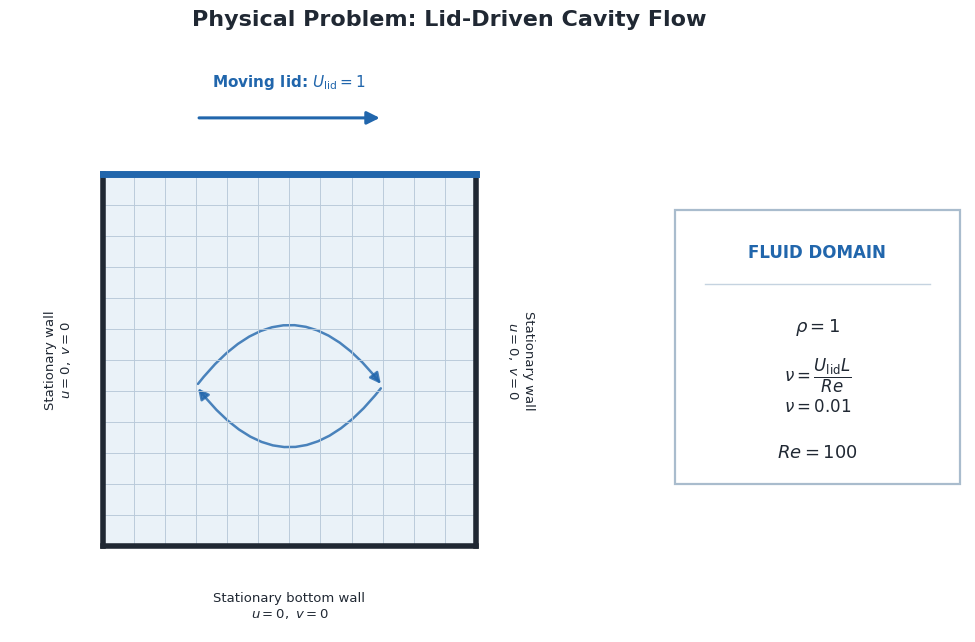

In [3]:

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, FancyArrowPatch

# ==========================================================
# Physical Problem: Lid-Driven Cavity Flow
# ==========================================================

RE = 100
U_LID = 1.0
LENGTH = 1.0
RHO = 1.0
NU = U_LID * LENGTH / RE

# Colors
blue = "#2166AC"
light_blue = "#EAF2F8"
grid_color = "#B8C9D9"
dark = "#202833"

# ==========================================================
# Figure layout: cavity on left, properties box on right
# ==========================================================

fig = plt.figure(figsize=(11, 7.5), facecolor="white")

# Main cavity axes
ax = fig.add_axes([0.08, 0.13, 0.55, 0.76])

ax.set_xlim(-0.25, 1.25)
ax.set_ylim(-0.23, 1.30)
ax.set_aspect("equal")
ax.axis("off")

# ==========================================================
# 1. Fluid domain
# ==========================================================

cavity = Rectangle(
    (0, 0), LENGTH, LENGTH,
    facecolor=light_blue,
    edgecolor="none"
)
ax.add_patch(cavity)

# Computational grid
N_GRID = 12

for value in np.linspace(0, LENGTH, N_GRID + 1):
    ax.plot(
        [value, value], [0, LENGTH],
        color=grid_color,
        linewidth=0.65
    )

    ax.plot(
        [0, LENGTH], [value, value],
        color=grid_color,
        linewidth=0.65
    )

# ==========================================================
# 2. Walls
# ==========================================================

# Stationary walls
ax.plot([0, 0], [0, LENGTH], color=dark, linewidth=4)
ax.plot([LENGTH, LENGTH], [0, LENGTH], color=dark, linewidth=4)
ax.plot([0, LENGTH], [0, 0], color=dark, linewidth=4)

# Moving lid
ax.plot(
    [0, LENGTH], [LENGTH, LENGTH],
    color=blue, linewidth=5
)

# ==========================================================
# 3. Moving lid arrow
# ==========================================================

ax.add_patch(
    FancyArrowPatch(
        (0.25, 1.15),
        (0.75, 1.15),
        arrowstyle="-|>",
        mutation_scale=19,
        linewidth=2.2,
        color=blue
    )
)

ax.text(
    0.5, 1.22,
    r"Moving lid: $U_{\mathrm{lid}}=1$",
    ha="center",
    va="bottom",
    fontsize=11,
    color=blue,
    fontweight="bold"
)

# ==========================================================
# 4. Schematic recirculation loop
# ==========================================================

ax.add_patch(
    FancyArrowPatch(
        (0.25, 0.43), (0.75, 0.43),
        connectionstyle="arc3,rad=-0.65",
        arrowstyle="-|>",
        mutation_scale=16,
        linewidth=1.8,
        color=blue,
        alpha=0.8
    )
)

ax.add_patch(
    FancyArrowPatch(
        (0.75, 0.43), (0.25, 0.43),
        connectionstyle="arc3,rad=-0.65",
        arrowstyle="-|>",
        mutation_scale=16,
        linewidth=1.8,
        color=blue,
        alpha=0.8
    )
)

# ==========================================================
# 5. Boundary labels
# ==========================================================

ax.text(
    -0.12, 0.5,
    "Stationary wall\n$u=0,\\ v=0$",
    rotation=90,
    ha="center",
    va="center",
    fontsize=9.5,
    color=dark
)

ax.text(
    1.12, 0.5,
    "Stationary wall\n$u=0,\\ v=0$",
    rotation=270,
    ha="center",
    va="center",
    fontsize=9.5,
    color=dark
)

ax.text(
    0.5, -0.12,
    "Stationary bottom wall\n$u=0,\\ v=0$",
    ha="center",
    va="top",
    fontsize=9.5,
    color=dark
)

# ==========================================================
# 6. Fluid properties box on the right
# ==========================================================

ax_prop = fig.add_axes([0.70, 0.32, 0.27, 0.38])

ax_prop.set_xlim(0, 1)
ax_prop.set_ylim(0, 1)
ax_prop.axis("off")

# Box
property_box = Rectangle(
    (0.02, 0.02), 0.96, 0.96,
    facecolor="white",
    edgecolor="#A9BCCD",
    linewidth=1.6
)

ax_prop.add_patch(property_box)

# Header
ax_prop.text(
    0.5, 0.83,
    "FLUID DOMAIN",
    ha="center",
    va="center",
    fontsize=12,
    fontweight="bold",
    color=blue
)

# Divider
ax_prop.plot(
    [0.12, 0.88], [0.72, 0.72],
    color="#C5D3E0",
    linewidth=1
)

# Fluid properties
ax_prop.text(
    0.5, 0.57,
    r"$\rho = 1$",
    ha="center",
    va="center",
    fontsize=13,
    color=dark
)

ax_prop.text(
    0.5, 0.40,
    r"$\nu = \dfrac{U_{\mathrm{lid}}L}{Re}$",
    ha="center",
    va="center",
    fontsize=12,
    color=dark
)

ax_prop.text(
    0.5, 0.29,
    r"$\nu = 0.01$",
    ha="center",
    va="center",
    fontsize=12,
    color=dark
)

ax_prop.text(
    0.5, 0.13,
    r"$Re = 100$",
    ha="center",
    va="center",
    fontsize=13,
    fontweight="bold",
    color=dark
)

# ==========================================================
# 7. Figure title
# ==========================================================

fig.suptitle(
    "Physical Problem: Lid-Driven Cavity Flow",
    fontsize=16,
    fontweight="bold",
    y=0.96,
    color=dark
)

# ==========================================================
# 8. Save output
# ==========================================================

plt.savefig(
    "lid_driven_cavity_physical_problem.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.savefig(
    "lid_driven_cavity_physical_problem.pdf",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()


## 2. Imports and Parameters

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.fft import dstn, idstn
%matplotlib inline

N = 65
RE = 100.0
LID_SPEED = 1.0
FINAL_TIME = 45.0
LENGTH = 1.0

## 3. Grid, Time Step and Initial Conditions
The grid spacing, viscosity and time step follow Section 1. Initially the fluid is at rest ($\omega=\psi=0$). The array `eigenvalues` holds $\lambda_{k,l}$ for the Poisson solver.

In [2]:
h = LENGTH / (N - 1)
nu = LID_SPEED * LENGTH / RE
dt_target = min(0.30 * h / LID_SPEED, 0.20 * h**2 / nu)
steps = int(np.ceil(FINAL_TIME / dt_target))
dt = FINAL_TIME / steps
x = np.linspace(0.0, LENGTH, N)
y = np.linspace(0.0, LENGTH, N)
omega = np.zeros((N, N))
psi = np.zeros_like(omega)
k = np.arange(1, N - 1)
eigenvalues = 4.0 / h**2 * (np.sin(np.pi * k[:, None] / (2 * (N - 1)))**2 + np.sin(np.pi * k[None, :] / (2 * (N - 1)))**2)

print(f"h = {h:.6f}, nu = {nu:.4f}")
print(f"dt_target = {dt_target:.7f}  (convective limit {0.30*h/LID_SPEED:.7f}, diffusive limit {0.20*h**2/nu:.7f})")
print(f"steps = {steps}, adjusted dt = {dt:.7f}")

h = 0.015625, nu = 0.0100
dt_target = 0.0046875  (convective limit 0.0046875, diffusive limit 0.0048828)
steps = 9600, adjusted dt = 0.0046875


## 4. Solver Functions


In [3]:
def solve_streamfunction(w):
    spectral = dstn(w[1:-1, 1:-1], type=1, norm="ortho")
    p = np.zeros_like(w)
    p[1:-1, 1:-1] = idstn(spectral / eigenvalues, type=1, norm="ortho")
    return p

def wall_vorticity(w, p):
    w[0, 1:-1] = -2.0 * p[1, 1:-1] / h**2
    w[-1, 1:-1] = -2.0 * p[-2, 1:-1] / h**2 - 2.0 * LID_SPEED / h
    w[1:-1, 0] = -2.0 * p[1:-1, 1] / h**2
    w[1:-1, -1] = -2.0 * p[1:-1, -2] / h**2

def rhs(w, p):
    c = w[1:-1, 1:-1]
    e, wst = w[1:-1, 2:], w[1:-1, :-2]
    n, s = w[2:, 1:-1], w[:-2, 1:-1]
    ue = (p[2:, 2:] + p[2:, 1:-1] - p[:-2, 2:] - p[:-2, 1:-1]) / (4 * h)
    uw = (p[2:, 1:-1] + p[2:, :-2] - p[:-2, 1:-1] - p[:-2, :-2]) / (4 * h)
    vn = -(p[2:, 2:] + p[1:-1, 2:] - p[2:, :-2] - p[1:-1, :-2]) / (4 * h)
    vs = -(p[1:-1, 2:] + p[:-2, 2:] - p[1:-1, :-2] - p[:-2, :-2]) / (4 * h)
    fe = ue * np.where(ue >= 0, c, e)
    fw = uw * np.where(uw >= 0, wst, c)
    fn = vn * np.where(vn >= 0, c, n)
    fs = vs * np.where(vs >= 0, s, c)
    convection = (fe - fw + fn - fs) / h
    diffusion = nu * (e + wst + n + s - 4 * c) / h**2
    return diffusion - convection, np.max(np.abs((ue - uw + vn - vs) / h))

## 5. Time Marching to Steady State


In [4]:
max_face_div = 0.0
for iteration in range(1, steps + 1):
    psi = solve_streamfunction(omega)
    wall_vorticity(omega, psi)
    rate, face_div = rhs(omega, psi)
    omega[1:-1, 1:-1] += dt * rate
    max_face_div = max(max_face_div, face_div)
print("Time marching finished:", steps, "steps")

Time marching finished: 9600 steps


## 6. Post-Processing


In [5]:
psi = solve_streamfunction(omega)
wall_vorticity(omega, psi)
u = np.zeros_like(psi)
v = np.zeros_like(psi)
u[1:-1, 1:-1] = (psi[2:, 1:-1] - psi[:-2, 1:-1]) / (2 * h)
v[1:-1, 1:-1] = -(psi[1:-1, 2:] - psi[1:-1, :-2]) / (2 * h)
u[-1, :] = LID_SPEED
rate, final_face_div = rhs(omega, psi)
steady_residual = float(np.max(np.abs(rate)))

## 7. Validation Against Ghia et al. (1982)
Centreline velocity profiles at $Re=100$ are compared with the benchmark tabulated values. The numerical profile (grid points on $x=0.5$ and $y=0.5$) is linearly interpolated to the benchmark coordinates; the RMSE over the 12 tabulated points is reported.

In [6]:
ghia_y = np.array([0.0, .1016, .1719, .2813, .4531, .5, .6172, .7344, .8516, .9531, .9688, 1.0])
ghia_u = np.array([0.0, -.06434, -.10150, -.15662, -.21090, -.20581, -.13641, .00332, .23151, .68717, .78871, 1.0])
ghia_x = np.array([0.0, .0625, .0938, .1563, .2266, .5, .8047, .8594, .9063, .9531, .9688, 1.0])
ghia_v = np.array([0.0, .09233, .12317, .16077, .17507, .05454, -.24533, -.22445, -.16914, -.08864, -.05906, 0.0])
uc = np.interp(ghia_y, y, u[:, N // 2])
vc = np.interp(ghia_x, x, v[N // 2, :])
rmse_u = np.sqrt(np.mean((uc - ghia_u)**2))
rmse_v = np.sqrt(np.mean((vc - ghia_v)**2))

## 8. Results

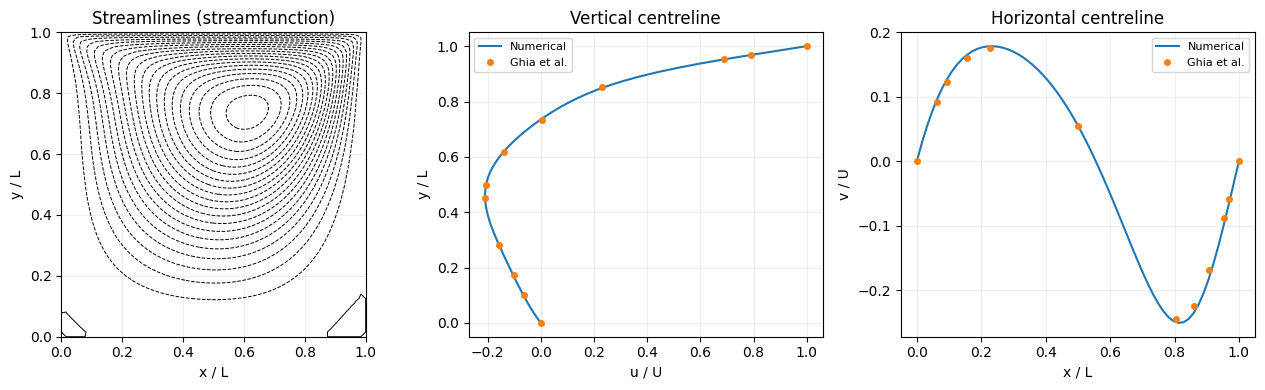

Re=100, N=65, steps=9600, dt=0.0046875, final_time=45
u_center=-0.205301, v_center=0.055471
Ghia_u_RMSE=0.003674, Ghia_v_RMSE=0.006526
max_FV_flux_divergence=7.105e-14, steady_vorticity_rate=1.327e-11
figure=experiment_9_cavity_output.png


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
axes[0].contour(x, y, psi, levels=22, colors="black", linewidths=.7)
axes[0].set(xlabel="x / L", ylabel="y / L", title="Streamlines (streamfunction)", aspect="equal")
axes[1].plot(u[:, N // 2], y, label="Numerical")
axes[1].plot(ghia_u, ghia_y, "o", ms=4, label="Ghia et al.")
axes[1].set(xlabel="u / U", ylabel="y / L", title="Vertical centreline")
axes[1].legend(fontsize=8)
axes[2].plot(x, v[N // 2, :], label="Numerical")
axes[2].plot(ghia_x, ghia_v, "o", ms=4, label="Ghia et al.")
axes[2].set(xlabel="x / L", ylabel="v / U", title="Horizontal centreline")
axes[2].legend(fontsize=8)
for ax in axes:
    ax.grid(alpha=.2)
fig.tight_layout()
fig.savefig("experiment_9_cavity_output.png", dpi=160)
plt.show()
plt.close(fig)
print(f"Re={RE:.0f}, N={N}, steps={steps}, dt={dt:.6g}, final_time={FINAL_TIME:g}")
print(f"u_center={u[N//2, N//2]:.6f}, v_center={v[N//2, N//2]:.6f}")
print(f"Ghia_u_RMSE={rmse_u:.6f}, Ghia_v_RMSE={rmse_v:.6f}")
print(f"max_FV_flux_divergence={max_face_div:.3e}, steady_vorticity_rate={steady_residual:.3e}")
print("figure=experiment_9_cavity_output.png")


## 9. Detailed Comparison Tables
Pointwise comparison against the Ghia et al. data (numerical values obtained by linear interpolation).

In [8]:
import pandas as pd, json
tab_u = pd.DataFrame({"y/L": ghia_y, "u (Ghia)": ghia_u, "u (present)": uc})
tab_u["abs. error"] = (tab_u["u (present)"] - tab_u["u (Ghia)"]).abs()
tab_v = pd.DataFrame({"x/L": ghia_x, "v (Ghia)": ghia_v, "v (present)": vc})
tab_v["abs. error"] = (tab_v["v (present)"] - tab_v["v (Ghia)"]).abs()
print("Vertical centreline (x = 0.5):")
display(tab_u.round(5))
print("Horizontal centreline (y = 0.5):")
display(tab_v.round(5))
print(f"Max |error|: u = {tab_u['abs. error'].max():.5f} at y={tab_u.loc[tab_u['abs. error'].idxmax(),'y/L']}, "
      f"v = {tab_v['abs. error'].max():.5f} at x={tab_v.loc[tab_v['abs. error'].idxmax(),'x/L']}")

Vertical centreline (x = 0.5):


,y/L,u (Ghia),u (present),abs. error
0,0.0000,0.00000,0.00000,0.00000
1,0.1016,-0.06434,-0.06599,0.00165
2,0.1719,-0.10150,-0.10310,0.00160
3,0.2813,-0.15662,-0.15668,0.00006
4,0.4531,-0.21090,-0.20933,0.00157
5,0.5000,-0.20581,-0.20530,0.00051
6,0.6172,-0.13641,-0.14035,0.00394
7,0.7344,0.00332,-0.00091,0.00423
8,0.8516,0.23151,0.23864,0.00713
9,0.9531,0.68717,0.69375,0.00658


Horizontal centreline (y = 0.5):


,x/L,v (Ghia),v (present),abs. error
0,0.0000,0.00000,0.00000,0.00000
1,0.0625,0.09233,0.09586,0.00353
2,0.0938,0.12317,0.12751,0.00434
3,0.1563,0.16077,0.16528,0.00451
4,0.2266,0.17507,0.17838,0.00331
5,0.5000,0.05454,0.05547,0.00093
6,0.8047,-0.24533,-0.24932,0.00399
7,0.8594,-0.22445,-0.23536,0.01091
8,0.9063,-0.16914,-0.18229,0.01315
9,0.9531,-0.08864,-0.09827,0.00963


Max |error|: u = 0.00713 at y=0.8516, v = 0.01315 at x=0.9063


## 10. Flow Features: Primary Vortex and Extrema


In [9]:
i_min, j_min = np.unravel_index(np.argmin(psi), psi.shape)
psi_min, xv, yv = psi[i_min, j_min], x[j_min], y[i_min]
uline, vline = u[:, N // 2], v[N // 2, :]
iu = np.argmin(uline[:-1])
features = {
    "psi_min": float(psi_min), "vortex_x": float(xv), "vortex_y": float(yv),
    "u_min_centreline": float(uline[iu]), "u_min_y": float(y[iu]),
    "v_max_centreline": float(vline.max()), "v_max_x": float(x[np.argmax(vline)]),
    "v_min_centreline": float(vline.min()), "v_min_x": float(x[np.argmin(vline)]),
    "omega_max_abs_interior": float(np.max(np.abs(omega[1:-1, 1:-1]))),
}
half = N // 2
iL, jL = np.unravel_index(np.argmax(psi[:half, :half]), (half, half))
iR, jR = np.unravel_index(np.argmax(psi[:half, half:]), (half, N - half)); jR += half
features.update({"psi_max_BL": float(psi[iL, jL]), "BL_x": float(x[jL]), "BL_y": float(y[iL]),
                 "psi_max_BR": float(psi[iR, jR]), "BR_x": float(x[jR]), "BR_y": float(y[iR])})
for kk, vv in features.items(): print(f"{kk:24s} {vv: .6f}")

psi_min                  -0.102912
vortex_x                  0.609375
vortex_y                  0.734375
u_min_centreline         -0.209337
u_min_y                   0.453125
v_max_centreline          0.178545
v_max_x                   0.234375
v_min_centreline         -0.250689
v_min_x                   0.812500
omega_max_abs_interior    31.342511
psi_max_BL                0.000003
BL_x                      0.031250
BL_y                      0.031250
psi_max_BR                0.000011
BR_x                      0.953125
BR_y                      0.062500


## 11. Vorticity and Speed Fields
Filled contours of vorticity $\omega$ and velocity magnitude $|\mathbf{u}|$ give a fuller picture than the streamlines alone.

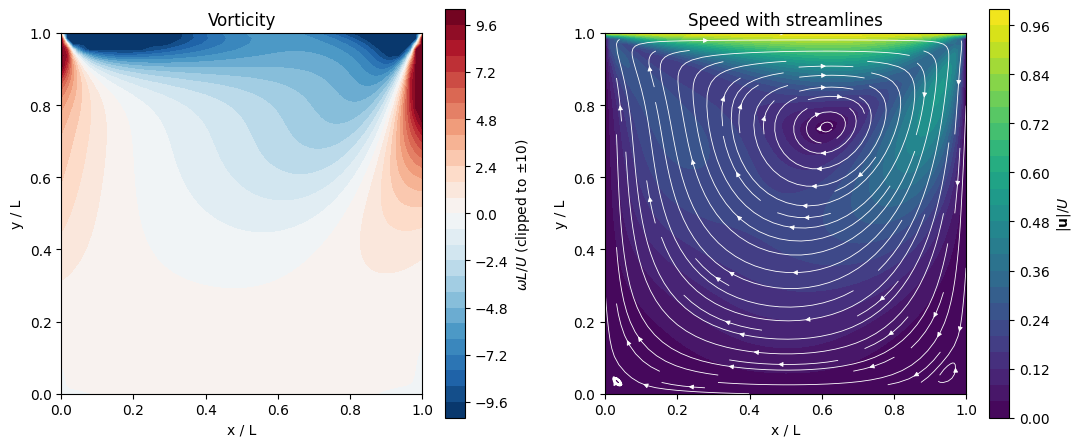

Unclipped vorticity range: -96.282 to 42.053 (the minimum sits on the lid next to the top-left corner, the maximum on the right wall just below the top-right corner: the corner singularities)


In [10]:
speed = np.hypot(u, v)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
cs = axes[0].contourf(x, y, np.clip(omega, -10, 10), levels=30, cmap="RdBu_r")
fig.colorbar(cs, ax=axes[0], label=r"$\omega L/U$ (clipped to ±10)")
axes[0].set(xlabel="x / L", ylabel="y / L", title="Vorticity", aspect="equal")
cs = axes[1].contourf(x, y, speed, levels=30, cmap="viridis")
axes[1].streamplot(x, y, u, v, color="white", density=1.1, linewidth=.6, arrowsize=.7)
fig.colorbar(cs, ax=axes[1], label=r"$|\mathbf{u}|/U$")
axes[1].set(xlabel="x / L", ylabel="y / L", title="Speed with streamlines", aspect="equal", xlim=(0, 1), ylim=(0, 1))
fig.tight_layout()
fig.savefig("experiment_9_fields.png", dpi=160)
plt.show()
print("Unclipped vorticity range:", omega.min().round(3), "to", omega.max().round(3), "(the minimum sits on the lid next to the top-left corner, the maximum on the right wall just below the top-right corner: the corner singularities)")

## 12. Convergence History


Reproduces main run to round-off (atol 1e-10): True
max |difference| = 1.2212453270876722e-13


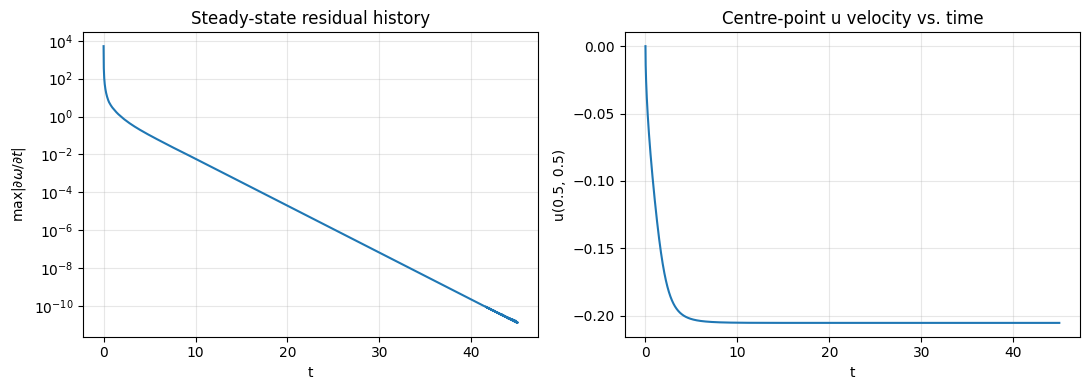

residual first below 1e-02 at t = 9.05
residual first below 1e-04 at t = 17.13
residual first below 1e-06 at t = 25.19
residual first below 1e-08 at t = 33.25


In [11]:
def run_with_history():
    w = np.zeros((N, N))
    hist_t, hist_res, hist_uc = [], [], []
    for it in range(1, steps + 1):
        p = solve_streamfunction(w)
        wall_vorticity(w, p)
        r, _ = rhs(w, p)
        w[1:-1, 1:-1] += dt * r
        hist_t.append(it * dt)
        hist_res.append(np.max(np.abs(r)))
        hist_uc.append((p[N//2 + 1, N//2] - p[N//2 - 1, N//2]) / (2 * h))
    return w, np.array(hist_t), np.array(hist_res), np.array(hist_uc)

omega_chk, ht, hres, huc = run_with_history()
print("Reproduces main run to round-off (atol 1e-10):", np.allclose(omega_chk, omega, atol=1e-10, rtol=0))
print("max |difference| =", np.max(np.abs(omega_chk - omega)))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].semilogy(ht, hres)
axes[0].set(xlabel="t", ylabel=r"$\max|\partial\omega/\partial t|$", title="Steady-state residual history")
axes[1].plot(ht, huc)
axes[1].set(xlabel="t", ylabel="u(0.5, 0.5)", title="Centre-point u velocity vs. time")
for ax in axes: ax.grid(alpha=.3)
fig.tight_layout()
fig.savefig("experiment_9_convergence.png", dpi=160)
plt.show()

for thr in (1e-2, 1e-4, 1e-6, 1e-8):
    idx = np.argmax(hres < thr)
    print(f"residual first below {thr:.0e} at t = {ht[idx]:.2f}" if hres[idx] < thr else f"residual never below {thr:.0e}")